# 2020 Summer Olympics Predictions — Reproduce & Extend (Reference Solution)

Reference: Dobkowski, *2020 Summer Olympics Predictions Using Machine Learning* (Stanford).

**Pipeline:** Kaggle athlete results + World Bank WDI → country-year table (1988–2016) → two-stage model
(binary classifier: *any medal?* → regressor: *how many?*).

| Split | Years |
|---|---|
| Model tuning (K-fold CV) | 1988–2008 |
| Validation / selection | 2012 |
| Test | 2016 (retrain on 1988–2012) |

**Assumptions made where the paper is silent
1. "Avg Std Dev [Medals]" is interpreted as **RMSE** = √(Eq. 1).
2. Regressors are trained on rows whose **true** label is medals > 0; the classifier gates predictions only at inference.
3. Negative predictions are clipped to 0.
4. "Total Medals" = total medals awarded at that Games; "Total Athletes" = the country's athlete count.
5. One medal per event per country (team events de-duplicated).

## 1. Setup

In [ ]:
!pip install -q wbgapi kagglehub statsmodels

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import (LogisticRegression, LinearRegression, Ridge,
                                  Lasso, PoissonRegressor)
from sklearn.svm import SVC, SVR
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
import statsmodels.api as sm

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 2. Load data
### 2a. Olympic results (Kaggle: *120 years of Olympic history*)

In [ ]:
try:
    import kagglehub
    path = kagglehub.dataset_download("heesoo37/120-years-of-olympic-history-athletes-and-results")
    ATH_CSV = os.path.join(path, "athlete_events.csv")
except Exception as e:
    print("kagglehub download failed -> upload athlete_events.csv manually.\n", e)
    from google.colab import files
    files.upload()
    ATH_CSV = "athlete_events.csv"

ath = pd.read_csv(ATH_CSV)
print(ath.shape)
ath.head()

100%|██████████| 5.43M/5.43M [00:00<00:00, 50.7MB/s]

Extracting files...


(271116, 15)


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.000,180.000,80.000,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.000,170.000,60.000,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.000,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.000,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.000,185.000,82.000,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


### 2b. Build the country-year Olympic table
1984 is loaded only to compute `Medals_Last_Games` for 1988; it is dropped afterwards.

In [ ]:
summer = ath[(ath.Season == "Summer") & ath.Year.between(1984, 2016)].copy()

# Athletes per country per Games (unique athlete IDs)
athletes = summer.groupby(["NOC", "Year"])["ID"].nunique().rename("Athletes")

# One medal per event per country (a relay team = 1 medal, not 4)
med = (summer.dropna(subset=["Medal"])
             .drop_duplicates(subset=["Year", "NOC", "Event", "Medal"]))
medals = med.groupby(["NOC", "Year"]).size().rename("Medals")

oly = pd.concat([athletes, medals], axis=1).reset_index()
oly["Medals"] = oly["Medals"].fillna(0).astype(int)

# Per-Games totals (computed BEFORE any rows are dropped)
oly["Total_Medals"]   = oly.groupby("Year")["Medals"].transform("sum")
oly["Total_Athletes"] = oly.groupby("Year")["Athletes"].transform("sum")
oly["Pct_Athletes"]   = oly["Athletes"] / oly["Total_Athletes"] * 100

# Medals at the previous Games (0 if the country did not compete / boycotted)
prev = oly[["NOC", "Year", "Medals"]].copy()
prev["Year"] += 4
prev = prev.rename(columns={"Medals": "Medals_Last_Games"})
oly = oly.merge(prev, on=["NOC", "Year"], how="left")
oly["Medals_Last_Games"] = oly["Medals_Last_Games"].fillna(0)

oly = oly[oly.Year >= 1988].reset_index(drop=True)

# Sanity check: 2016 top 5 should be close to official (USA 121, CHN 70, GBR 67, RUS 56, GER 42)
oly[oly.Year == 2016].nlargest(5, "Medals")[["NOC", "Medals", "Athletes"]]

,NOC,Medals,Athletes
1477,USA,121,555
300,CHN,70,392
523,GBR,67,360
1195,RUS,56,284
493,FRA,42,392


### 2c. World Development Indicators (World Bank API)
Note: WDI series are revised over time, so values will not exactly match the paper's 2021 download.

In [ ]:
import wbgapi as wb

SERIES = {
    "NY.GDP.MKTP.CD":    "GDP",
    "NY.GDP.PCAP.CD":    "GDP_Per_Capita",
    "NY.GDP.MKTP.KD.ZG": "GDP_Growth",
    "SP.POP.TOTL":       "Pop",
    "SP.POP.GROW":       "Pop_Growth",
    "AG.LND.TOTL.K2":    "Area",
}
YEARS = list(range(1988, 2017, 4))

wdi = (wb.data.DataFrame(list(SERIES), economy="all", time=YEARS,
                         labels=False, columns="series")
         .reset_index()
         .rename(columns={"economy": "ISO3", "time": "Year", **SERIES}))
wdi["Year"] = wdi["Year"].astype(str).str.replace("YR", "").astype(int)

world = wdi[wdi.ISO3 == "WLD"].set_index("Year")
wdi["Pct_World_GDP"] = wdi["GDP"] / wdi["Year"].map(world["GDP"]) * 100
wdi["Pct_World_Pop"] = wdi["Pop"] / wdi["Year"].map(world["Pop"]) * 100
print(wdi.shape)
wdi.head()

(2120, 10)


,ISO3,Year,Area,GDP,GDP_Growth,GDP_Per_Capita,Pop_Growth,Pop,Pct_World_GDP,Pct_World_Pop
0,ABW,1988,180.000,"596,648,044.693",18.649,"10,056.261",0.290,"59,331.000",0.003,0.001
1,ABW,1992,180.000,"958,659,217.877",5.882,"13,892.605",4.610,"69,005.000",0.004,0.001
2,ABW,1996,180.000,"1,379,888,268.156",1.186,"16,620.955",3.951,"83,021.000",0.004,0.001
3,ABW,2000,180.000,"1,873,452,513.966",7.623,"20,681.023",1.031,"90,588.000",0.006,0.001
4,ABW,2004,180.000,"2,254,830,726.257",7.294,"23,700.632",2.135,"95,138.000",0.005,0.001


### 2d. Resolve country codes (IOC → ISO3)
IOC and ISO3 codes agree for most countries; the dictionary covers the common differences.
Historical NOCs (URS, EUN, GDR, FRG, TCH, YUG) and Taiwan (TPE) have no WDI rows and drop out,
which mirrors the paper's "drop rows with nulls".

In [ ]:
IOC_TO_ISO3 = {
 "ALG":"DZA","ANG":"AGO","ANT":"ATG","ARU":"ABW","ASA":"ASM","BAH":"BHS","BAN":"BGD","BAR":"BRB",
 "BER":"BMU","BHU":"BTN","BIZ":"BLZ","BOT":"BWA","BRU":"BRN","BUL":"BGR","BUR":"BFA","CAM":"KHM",
 "CAY":"CYM","CGO":"COG","CHA":"TCD","CHI":"CHL","CRC":"CRI","CRO":"HRV","DEN":"DNK","ESA":"SLV",
 "FIJ":"FJI","GAM":"GMB","GBS":"GNB","GEQ":"GNQ","GER":"DEU","GRE":"GRC","GRN":"GRD","GUA":"GTM",
 "GUI":"GIN","HAI":"HTI","HON":"HND","INA":"IDN","IRI":"IRN","ISV":"VIR","IVB":"VGB","KOS":"XKX",
 "KSA":"SAU","KUW":"KWT","LAT":"LVA","LBA":"LBY","LES":"LSO","LIB":"LBN","MAD":"MDG","MAS":"MYS",
 "MAW":"MWI","MGL":"MNG","MON":"MCO","MRI":"MUS","MTN":"MRT","MYA":"MMR","NCA":"NIC","NED":"NLD",
 "NEP":"NPL","NGR":"NGA","NIG":"NER","OMA":"OMN","PAR":"PRY","PHI":"PHL","PLE":"PSE","POR":"PRT",
 "PUR":"PRI","RSA":"ZAF","SAM":"WSM","SEY":"SYC","SIN":"SGP","SKN":"KNA","SLO":"SVN","SOL":"SLB",
 "SRI":"LKA","SUD":"SDN","SUI":"CHE","TAN":"TZA","TGA":"TON","TOG":"TGO","TRI":"TTO","UAE":"ARE",
 "URU":"URY","VAN":"VUT","VIE":"VNM","VIN":"VCT","ZAM":"ZMB","ZIM":"ZWE",
}
oly["ISO3"] = oly["NOC"].map(IOC_TO_ISO3).fillna(oly["NOC"])

unmatched = sorted(set(oly.ISO3) - set(wdi.ISO3))
print(f"{len(unmatched)} NOCs with no WDI match (dropped):", unmatched)

df_raw = oly.merge(wdi, on=["ISO3", "Year"], how="inner")

14 NOCs with no WDI match (dropped): ['AHO', 'COK', 'EUN', 'FRG', 'GDR', 'IOA', 'ROT', 'SCG', 'TCH', 'TPE', 'URS', 'YAR', 'YMD', 'YUG']


## 3. Features, null removal, split

In [ ]:
FEATURES = ["Year", "GDP", "GDP_Per_Capita", "GDP_Growth", "Pct_World_GDP",
            "Pop", "Pct_World_Pop", "Pop_Growth", "Area",
            "Medals_Last_Games", "Total_Medals", "Athletes", "Pct_Athletes"]
TARGET = "Medals"

df = df_raw.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print(f"Rows before null drop: {len(df_raw)}, after: {len(df)}")

tune = df[df.Year <= 2008]
val  = df[df.Year == 2012]
test = df[df.Year == 2016]
tv   = df[df.Year <= 2012]          # tuning + validation, used for final retrain
for n, d in [("tune", tune), ("val", val), ("test", test)]:
    print(f"{n:5s} rows={len(d):4d}  zero-medal share={(d.Medals == 0).mean():.2f}")

Rows before null drop: 1503, after: 1434
tune  rows=1040  zero-medal share=0.61
val   rows= 197  zero-medal share=0.58
test  rows= 197  zero-medal share=0.58


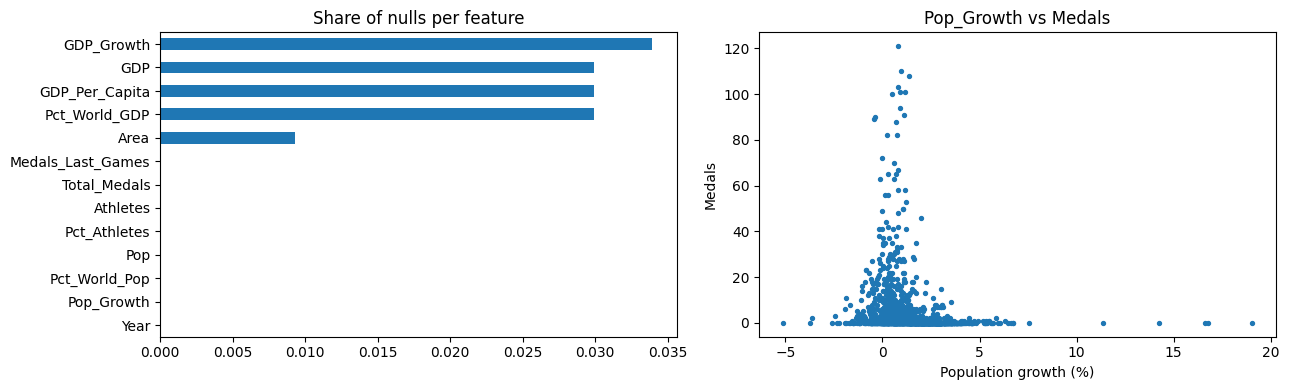

In [ ]:
# Paper Fig. 1 analogue: nulls per feature, and Fig. 2 analogue: feature vs medals
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df_raw[FEATURES].isna().mean().sort_values().plot.barh(ax=ax[0], title="Share of nulls per feature")
ax[1].scatter(df.Pop_Growth, df.Medals, s=8)
ax[1].set(title="Pop_Growth vs Medals", xlabel="Population growth (%)", ylabel="Medals")
plt.tight_layout(); plt.show()

## 4. Metrics
- **Eq. 1** → reported as RMSE (√MSE)
- **Eq. 2** → squared error on each Games' top-10 actual medal winners, divided by *n* (as written in the paper)

In [ ]:
def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def top10_loss(y, p, years):
    y, p, years = map(np.asarray, (y, p, years))
    mask = np.zeros(len(y), dtype=bool)
    for yr in np.unique(years):
        idx = np.where(years == yr)[0]
        mask[idx[np.argsort(-y[idx])[:10]]] = True
    return float(np.sum(((p - y) ** 2) * mask) / len(y))

def combined_loss(y, p, years):           # selection criterion in Sec. 6
    return float(np.mean((np.asarray(y) - np.asarray(p)) ** 2) + 0.25 * top10_loss(y, p, years))

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def tune_model(est, grid, kind, X, y, scoring):
    if kind == "grid":
        s = GridSearchCV(est, grid, cv=cv, scoring=scoring, n_jobs=-1)
    else:
        s = RandomizedSearchCV(est, grid, n_iter=30, cv=cv, scoring=scoring,
                               n_jobs=-1, random_state=SEED)
    s.fit(X, y)
    return s.best_estimator_, s.best_params_

def scaled(model):
    return Pipeline([("sc", StandardScaler()), ("m", model)])

## 5. Stage 1 — Classifiers (medal / no medal)

In [ ]:
X_tune, X_val, X_test = tune[FEATURES], val[FEATURES], test[FEATURES]
yc_tune, yc_val = (tune.Medals > 0).astype(int), (val.Medals > 0).astype(int)

clf_specs = {
    "Logistic Reg.": (scaled(LogisticRegression(max_iter=5000)),
                      {"m__C": np.logspace(-3, 3, 13)}, "grid"),
    "SVM Clf":       (scaled(SVC()),
                      {"m__C": [0.1, 1, 10, 100], "m__kernel": ["linear", "rbf", "poly", "sigmoid"]}, "grid"),
    "Gaussian NB":   (scaled(GaussianNB()),
                      {"m__var_smoothing": np.logspace(-12, -1, 12)}, "grid"),
    "MLP":           (scaled(MLPClassifier(max_iter=2000, random_state=SEED)),
                      {"m__hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32)],
                       "m__activation": ["relu", "tanh", "logistic"],
                       "m__alpha": loguniform(1e-5, 1e-1)}, "random"),
    "Random Forest": (RandomForestClassifier(random_state=SEED),
                      {"n_estimators": randint(100, 500), "max_depth": [None, 4, 6, 8, 12],
                       "min_samples_leaf": randint(1, 10)}, "random"),
}
REPORTED_CLF = {"Logistic Reg.": 0.877, "SVM Clf": 0.884, "Random Forest": 0.877,
                "Gaussian NB": 0.891, "MLP": 0.855}

clfs, rows = {}, []
for name, (est, grid, kind) in clf_specs.items():
    best, params = tune_model(est, grid, kind, X_tune, yc_tune, "accuracy")
    clfs[name] = best
    pv = best.predict(X_val)
    rows.append({"Classifier": name, "Reported Acc": REPORTED_CLF[name],
                 "Our Acc": accuracy_score(yc_val, pv), "Our F1": f1_score(yc_val, pv)})
clf_table = pd.DataFrame(rows)
print(f"Majority-class baseline accuracy on 2012: {max(yc_val.mean(), 1 - yc_val.mean()):.3f}")
clf_table

Majority-class baseline accuracy on 2012: 0.579


,Classifier,Reported Acc,Our Acc,Our F1
0,Logistic Reg.,0.877,0.878,0.846
1,SVM Clf,0.884,0.863,0.828
2,Gaussian NB,0.891,0.868,0.833
3,MLP,0.855,0.883,0.859
4,Random Forest,0.877,0.878,0.854


## 6. Stage 2 — Regressors (gated by the classifier)
Regressors are trained on 1988–2008 rows with medals > 0. At prediction time, rows the classifier
labels 0 get a prediction of 0. Gate = Gaussian NB (the paper's best classifier for Table 3).
`before`/`after` columns reproduce Fig. 4.

In [ ]:
GATE_NAME = "Gaussian NB"
gate = clfs[GATE_NAME]
pos = tune[tune.Medals > 0]
X_pos, y_pos = pos[FEATURES], pos.Medals

def two_stage_predict(clf, reg, X):
    g = clf.predict(X)
    return np.clip(np.where(g == 1, reg.predict(X), 0.0), 0, None)

reg_specs = {
    "Linear":        (scaled(LinearRegression()), {}, "grid"),
    "Ridge":         (scaled(Ridge()), {"m__alpha": np.logspace(-3, 3, 25)}, "grid"),
    "Lasso":         (scaled(Lasso(max_iter=50000)), {"m__alpha": np.logspace(-3, 1, 25)}, "grid"),
    "Poisson":       (scaled(PoissonRegressor(max_iter=3000)), {"m__alpha": np.logspace(-4, 1, 12)}, "grid"),
    "SVM Reg":       (scaled(SVR()), {"m__kernel": ["linear", "rbf", "poly", "sigmoid"],
                                      "m__C": [1, 10, 100], "m__epsilon": [0.1, 0.5, 1.0]}, "grid"),
    "Random Forest": (RandomForestRegressor(random_state=SEED),
                      {"n_estimators": randint(100, 500), "max_depth": [None, 4, 6, 8, 12],
                       "min_samples_leaf": randint(1, 8), "max_features": [1.0, 0.7, 0.5, "sqrt"]}, "random"),
}
REPORTED_REG = {"Weighted LR": 2.63, "SVM Reg": 2.50, "Random Forest": 2.20,
                "Poisson": 3.75, "Lasso": 2.87, "Ridge": 2.27}

regs, rows = {}, []
for name, (est, grid, kind) in reg_specs.items():
    default = clone(est).fit(X_pos, y_pos)
    best, params = tune_model(est, grid, kind, X_pos, y_pos, "neg_mean_squared_error")
    regs[name] = best
    p_before = two_stage_predict(gate, default, X_val)
    p_after  = two_stage_predict(gate, best, X_val)
    rows.append({"Regressor": name, "Reported RMSE": REPORTED_REG.get(name, np.nan),
                 "Before tuning": rmse(val.Medals, p_before), "After tuning": rmse(val.Medals, p_after),
                 "Top-10 loss (Eq.2)": top10_loss(val.Medals, p_after, val.Year),
                 "Combined": combined_loss(val.Medals, p_after, val.Year), "Params": params})
reg_table = pd.DataFrame(rows)
reg_table

,Regressor,Reported RMSE,Before tuning,After tuning,Top-10 loss (Eq.2),Combined,Params
0,Linear,NaN,2.871,2.871,2.747,8.927,{}
1,Ridge,2.270,2.928,2.944,2.811,9.369,{'m__alpha': 17.78279410038923}
2,Lasso,2.870,3.012,2.875,2.686,8.938,{'m__alpha': 0.1467799267622069}
3,Poisson,3.750,3.857,3.809,8.808,16.714,{'m__alpha': 10.0}
4,SVM Reg,2.500,10.547,2.740,4.213,8.561,"{'m__C': 1, 'm__epsilon': 1.0, 'm__kernel': 'l..."
5,Random Forest,2.200,2.731,2.750,4.526,8.695,"{'max_depth': None, 'max_features': 0.5, 'min_..."


### 6a. Locally weighted linear regression (Eq. 4)
w⁽ⁱ⁾ = exp(−(y⁽ⁱ⁾ − y)² / 2τ²), with the paper's y = 50, τ = 1.

**Flag for the report:** with τ = 1 almost every weight underflows to ~0 (a country with 45 medals gets
e^(−12.5)), so the fit is driven by a handful of rows. The paper's τ may be in different units. We run the
literal setting and a τ sweep chosen on the 2012 combined loss.

In [ ]:
class WeightedLR:
    def __init__(self, y0=50, tau=1.0):
        self.y0, self.tau = y0, tau
    def fit(self, X, y):
        w = np.exp(-((np.asarray(y) - self.y0) ** 2) / (2 * self.tau ** 2))
        w = np.maximum(w, 1e-12)                      # avoid all-zero weights
        self.model = scaled(LinearRegression()).fit(X, y, m__sample_weight=w)
        return self
    def predict(self, X):
        return self.model.predict(X)

rows = []
for tau in [1, 5, 10, 20, 30, 50, 100]:
    m = WeightedLR(50, tau).fit(X_pos, y_pos)
    p = two_stage_predict(gate, m, X_val)
    rows.append({"tau": tau, "RMSE": rmse(val.Medals, p), "Combined": combined_loss(val.Medals, p, val.Year)})
wlr_sweep = pd.DataFrame(rows); display(wlr_sweep)

best_tau = wlr_sweep.loc[wlr_sweep.Combined.idxmin(), "tau"]
regs["Weighted LR"] = WeightedLR(50, best_tau).fit(X_pos, y_pos)
p_wlr = two_stage_predict(gate, regs["Weighted LR"], X_val)
reg_table = pd.concat([reg_table, pd.DataFrame([{
    "Regressor": f"Weighted LR", "Reported RMSE": 2.63,
    "Before tuning": wlr_sweep.loc[wlr_sweep.tau == 1, "RMSE"].item(),   # paper's literal tau=1
    "After tuning": rmse(val.Medals, p_wlr),
    "Top-10 loss (Eq.2)": top10_loss(val.Medals, p_wlr, val.Year),
    "Combined": combined_loss(val.Medals, p_wlr, val.Year), "Params": {"y0": 50, "tau": best_tau}}])],
    ignore_index=True)

,tau,RMSE,Combined
0,1,14.923,273.811
1,5,13.820,193.656
2,10,4.785,24.299
3,20,3.242,11.153
4,30,2.990,9.585
5,50,2.899,9.062
6,100,2.876,8.954


### 6b. Reproduction table — Table 3 (Reported vs Ours, 2012 validation)

,Classifier,Reported Acc,Our Acc,Our F1
0,Logistic Reg.,0.877,0.878,0.846
1,SVM Clf,0.884,0.863,0.828
2,Gaussian NB,0.891,0.868,0.833
3,MLP,0.855,0.883,0.859
4,Random Forest,0.877,0.878,0.854


,Regressor,Reported RMSE,Our RMSE,Top-10 loss (Eq.2),Combined,Diff
4,SVM Reg,2.500,2.740,4.213,8.561,0.240
5,Random Forest,2.200,2.750,4.526,8.695,0.550
0,Linear,NaN,2.871,2.747,8.927,NaN
2,Lasso,2.870,2.875,2.686,8.938,0.005
6,Weighted LR,2.630,2.876,2.718,8.954,0.246
1,Ridge,2.270,2.944,2.811,9.369,0.674
3,Poisson,3.750,3.809,8.808,16.714,0.059


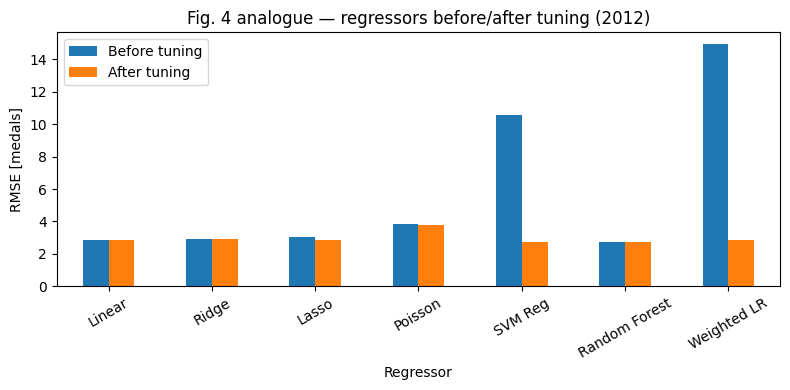

In [ ]:
table3 = reg_table[["Regressor", "Reported RMSE", "After tuning", "Top-10 loss (Eq.2)", "Combined"]] \
           .rename(columns={"After tuning": "Our RMSE"})
table3["Diff"] = table3["Our RMSE"] - table3["Reported RMSE"]
display(clf_table)
display(table3.sort_values("Combined"))

ax = reg_table.set_index("Regressor")[["Before tuning", "After tuning"]].plot.bar(figsize=(8, 4), rot=30)
ax.set(ylabel="RMSE [medals]", title="Fig. 4 analogue — regressors before/after tuning (2012)")
plt.tight_layout(); plt.show()

## 7. Final model on the 2016 test set
The paper picks Gaussian NB + Ridge using Eq.1 + 0.25·Eq.2. We report **both** the paper's choice and
the model our own selection picks, each retrained on 1988–2012. Baseline = plain linear regression, no classifier.

In [ ]:
our_pick = table3.sort_values("Combined").iloc[0]["Regressor"]
print("Our selection by combined loss:", our_pick)

def retrain_two_stage(reg_name):
    clf = clone(clfs[GATE_NAME]).fit(tv[FEATURES], (tv.Medals > 0).astype(int))
    pos_tv = tv[tv.Medals > 0]
    if reg_name == "Weighted LR":
        reg = WeightedLR(50, best_tau).fit(pos_tv[FEATURES], pos_tv.Medals)
    else:
        reg = clone(regs[reg_name]).fit(pos_tv[FEATURES], pos_tv.Medals)
    return clf, reg

test_preds = {}
for name in dict.fromkeys(["Ridge", our_pick]):
    c, r = retrain_two_stage(name)
    test_preds[f"GNB + {name}"] = two_stage_predict(c, r, X_test)

baseline = scaled(LinearRegression()).fit(tv[FEATURES], tv.Medals)
test_preds["Baseline linear (no classifier)"] = np.clip(baseline.predict(X_test), 0, None)

REPORTED_TEST = {"GNB + Ridge": 2.26, "Baseline linear (no classifier)": 3.25}
final_table = pd.DataFrame([{"Model": k, "Reported RMSE": REPORTED_TEST.get(k, np.nan),
                             "Our RMSE": rmse(test.Medals, p),
                             "Top-10 loss": top10_loss(test.Medals, p, test.Year)}
                            for k, p in test_preds.items()])
final_table

Our selection by combined loss: SVM Reg


,Model,Reported RMSE,Our RMSE,Top-10 loss
0,GNB + Ridge,2.260,3.753,5.374
1,GNB + SVM Reg,NaN,2.747,3.188
2,Baseline linear (no classifier),3.250,3.723,5.474


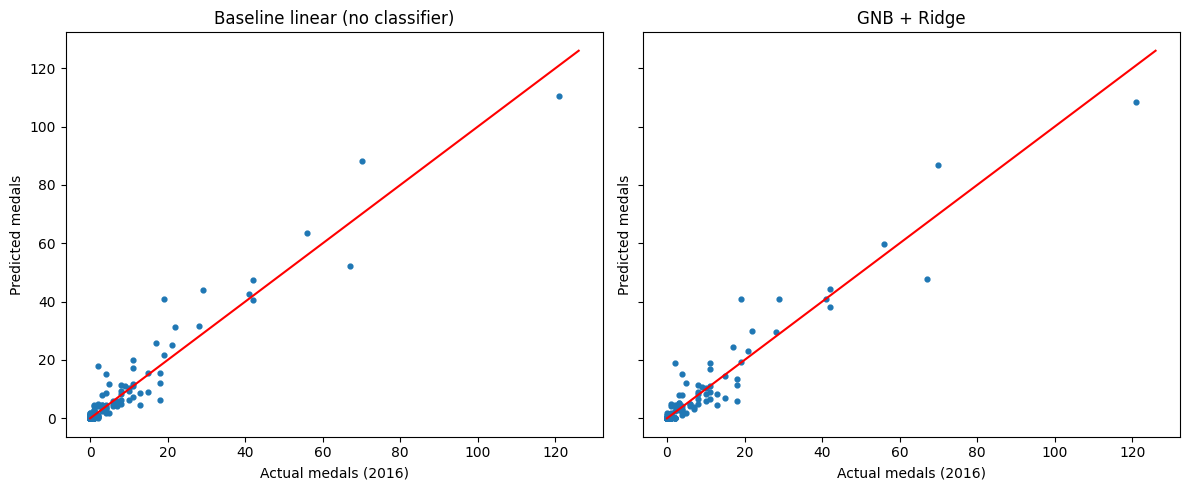

,NOC,Medals,Predicted
1372,USA,121,108.500
280,CHN,70,87.000
483,GBR,67,47.700
1114,RUS,56,59.600
454,FRA,42,38.100


In [ ]:
# Fig. 3 / Fig. 5 analogue + Table 4 analogue
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for a, key in zip(ax, ["Baseline linear (no classifier)", "GNB + Ridge"]):
    a.scatter(test.Medals, test_preds[key], s=12)
    lim = max(test.Medals.max(), test_preds[key].max()) + 5
    a.plot([0, lim], [0, lim], "r-")
    a.set(title=key, xlabel="Actual medals (2016)", ylabel="Predicted medals")
plt.tight_layout(); plt.show()

top5 = test.assign(Predicted=test_preds["GNB + Ridge"].round(1)) \
           .nlargest(5, "Medals")[["NOC", "Medals", "Predicted"]]
top5

> **Discussion prompt:** the paper's Table 4 lists 2016 "actual" counts (USA 103, China 89, …) that do not match
> official results or the paper's own Fig. 3. Compare against the top-5 table above and discuss in the report.

## 8. Extension — Negative Binomial regression

**Why:** The paper's Poisson model did worst (3.75) because Poisson forces variance = mean, while medal
counts are heavily **overdispersed** (many zeros, a few countries with 100+). Negative Binomial adds a
dispersion parameter α (Var = μ + αμ²), so it can model zeros and large counts in one model without a
separate classifier.

**Design choice:** with a log link, raw GDP/population produce exploding predictions for the largest countries,
so heavily skewed features are `log1p`-transformed before scaling. (This likely also hurt the paper's Poisson model.)

In [ ]:
LOG_COLS = ["GDP", "GDP_Per_Capita", "Pop", "Area", "Athletes", "Medals_Last_Games", "Total_Medals"]

def nb_design(d, scaler=None):
    X = d[FEATURES].copy()
    for c in LOG_COLS:
        X[c] = np.log1p(X[c].clip(lower=0))
    if scaler is None:
        scaler = StandardScaler().fit(X)
    return sm.add_constant(scaler.transform(X), has_constant="add"), scaler

# Step 1: evidence of overdispersion (Poisson GLM dispersion statistic; ~1 means no overdispersion)
Xd, sc = nb_design(tune)
pois = sm.GLM(tune.Medals.values, Xd, family=sm.families.Poisson()).fit()
print(f"Poisson dispersion (Pearson chi2 / df): {pois.pearson_chi2 / pois.df_resid:.2f}")

def fit_nb(train):
    X, sc = nb_design(train)
    m = sm.NegativeBinomial(train.Medals.values, X).fit(method="bfgs", maxiter=5000, disp=0)
    return m, sc

def predict_nb(m, sc, d):
    X, _ = nb_design(d, sc)
    return m.predict(X)

nb_m, nb_sc = fit_nb(tune)
print(f"Estimated alpha (dispersion): {nb_m.params[-1]:.3f}")

Poisson dispersion (Pearson chi2 / df): 1.56
Estimated alpha (dispersion): 0.215


In [ ]:
# Validation (2012) — trained on 1988–2008, same as Table 3
p_nb_val      = predict_nb(nb_m, nb_sc, val)
p_nb_gate_val = np.where(gate.predict(X_val) == 1, p_nb_val, 0.0)

# Test (2016) — retrained on 1988–2012, same as Section 7
nb_tv, nb_tv_sc = fit_nb(tv)
clf_tv = clone(clfs[GATE_NAME]).fit(tv[FEATURES], (tv.Medals > 0).astype(int))
p_nb_test      = predict_nb(nb_tv, nb_tv_sc, test)
p_nb_gate_test = np.where(clf_tv.predict(X_test) == 1, p_nb_test, 0.0)
test_preds["Neg. Binomial (standalone)"] = p_nb_test
test_preds["GNB + Neg. Binomial"]        = p_nb_gate_test

ext_table = pd.DataFrame([
    {"Model": "Neg. Binomial (standalone)", "Val RMSE 2012": rmse(val.Medals, p_nb_val),
     "Test RMSE 2016": rmse(test.Medals, p_nb_test)},
    {"Model": "GNB + Neg. Binomial", "Val RMSE 2012": rmse(val.Medals, p_nb_gate_val),
     "Test RMSE 2016": rmse(test.Medals, p_nb_gate_test)},
])
ext_table

,Model,Val RMSE 2012,Test RMSE 2016
0,Neg. Binomial (standalone),3.330,5.007
1,GNB + Neg. Binomial,3.341,5.003


## 9. Ablation — remove `Athletes` / `Pct_Athletes`
How much of the result comes from team size rather than economic indicators?

In [ ]:
FEAT_NO_ATH = [f for f in FEATURES if f not in ("Athletes", "Pct_Athletes")]
clf_a = clone(clfs[GATE_NAME]).fit(tv[FEAT_NO_ATH], (tv.Medals > 0).astype(int))
pos_tv = tv[tv.Medals > 0]
reg_a = clone(regs["Ridge"]).fit(pos_tv[FEAT_NO_ATH], pos_tv.Medals)
p_abl = np.clip(np.where(clf_a.predict(test[FEAT_NO_ATH]) == 1, reg_a.predict(test[FEAT_NO_ATH]), 0), 0, None)
print(f"GNB + Ridge without athlete features — test RMSE: {rmse(test.Medals, p_abl):.2f} "
      f"(with: {rmse(test.Medals, test_preds['GNB + Ridge']):.2f})")

GNB + Ridge without athlete features — test RMSE: 3.73 (with: 3.75)


## 10. Final comparison (2016 test set, identical rows and metric for every model)

In [ ]:
summary = pd.DataFrame([{"Model": k,
                         "Reported RMSE": {"GNB + Ridge": 2.26, "Baseline linear (no classifier)": 3.25}.get(k, np.nan),
                         "Our RMSE": rmse(test.Medals, p),
                         "Top-10 loss (Eq.2)": top10_loss(test.Medals, p, test.Year),
                         "Source": "Extension" if "Binomial" in k else "Reproduction"}
                        for k, p in test_preds.items()]).sort_values("Our RMSE")
summary

,Model,Reported RMSE,Our RMSE,Top-10 loss (Eq.2),Source
1,GNB + SVM Reg,NaN,2.747,3.188,Reproduction
2,Baseline linear (no classifier),3.250,3.723,5.474,Reproduction
0,GNB + Ridge,2.260,3.753,5.374,Reproduction
4,GNB + Neg. Binomial,NaN,5.003,6.881,Extension
3,Neg. Binomial (standalone),NaN,5.007,6.881,Extension
